In [1]:
!pip install -q ultralytics onnx onnxruntime scikit-learn seaborn matplotlib

import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device: {torch.cuda.get_device_name(0)}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.1/23.1 MB 65.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.9/68.9 kB 2.7 MB/s eta 0:00:00
PyTorch Version: 2.10.0+cu128
CUDA Available: True
GPU Device: Tesla T4


In [2]:
import os
import glob

# Search for the dataset path attached to your Kaggle environment
possible_paths = [
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset",
    "/kaggle/input/brain-tumor-mri-dataset",
]

DATASET_DIR = None
for p in possible_paths:
    if os.path.exists(os.path.join(p, "Training")):
        DATASET_DIR = p
        break

# Fallback search if path differs slightly
if not DATASET_DIR:
    matches = glob.glob("/kaggle/input/**/Training", recursive=True)
    if matches:
        DATASET_DIR = os.path.dirname(matches[0])

assert DATASET_DIR is not None, "Could not locate Training directory in /kaggle/input/"
print(f"Dataset root identified at: {DATASET_DIR}")

train_path = os.path.join(DATASET_DIR, "Training")
test_path = os.path.join(DATASET_DIR, "Testing")

classes = sorted(os.listdir(train_path))
print(f"Detected Classes ({len(classes)}): {classes}")

for cls in classes:
    n_train = len(glob.glob(f"{train_path}/{cls}/*"))
    n_test = len(glob.glob(f"{test_path}/{cls}/*"))
    print(f"  {cls:12} -> Train: {n_train:4d} | Test: {n_test:4d}")

Dataset root identified at: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
Detected Classes (4): ['glioma', 'meningioma', 'notumor', 'pituitary']
  glioma       -> Train: 1400 | Test:  400
  meningioma   -> Train: 1400 | Test:  400
  notumor      -> Train: 1400 | Test:  400
  pituitary    -> Train: 1400 | Test:  400


In [5]:
import os
from ultralytics import YOLO

# 1. Create a writable dataset layout in /kaggle/working/ using instant symlinks
DATASET_WORK = "/kaggle/working/dataset"
os.makedirs(DATASET_WORK, exist_ok=True)

train_link = os.path.join(DATASET_WORK, "train")
val_link = os.path.join(DATASET_WORK, "val")
test_link = os.path.join(DATASET_WORK, "test")

# Link 'Training' -> 'train' and 'Testing' -> 'val' / 'test'
if not os.path.exists(train_link):
    os.symlink(os.path.join(DATASET_DIR, "Training"), train_link)
if not os.path.exists(val_link):
    os.symlink(os.path.join(DATASET_DIR, "Testing"), val_link)
if not os.path.exists(test_link):
    os.symlink(os.path.join(DATASET_DIR, "Testing"), test_link)

print("Dataset symlinks created successfully:")
print(f"  train: {train_link} -> {os.path.join(DATASET_DIR, 'Training')}")
print(f"  val:   {val_link}   -> {os.path.join(DATASET_DIR, 'Testing')}")

# 2. Train YOLOv8 on the symlinked dataset
model = YOLO('yolov8n-cls.pt')

results = model.train(
    data=DATASET_WORK,
    epochs=15,
    imgsz=224,
    batch=32,
    workers=4,
    fliplr=0.5,
    flipud=0.0,
    cos_lr=True,
    project="/kaggle/working/brain_tumor_run",
    name="yolov8_mri",
    exist_ok=True
)

Dataset symlinks created successfully:
  train: /kaggle/working/dataset/train -> /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
  val:   /kaggle/working/dataset/val   -> /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
Ultralytics 8.4.143 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/15     0.492G     0.2902         32        224: 100% ━━━━━━━━━━━━ 175/175 6.6it/s 26.5s0.2ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 25/25 6.3it/s 4.0s0.3ss
                   all      0.913          1

      Epoch    GPU_mem       loss  Instances       Size
       3/15     0.492G     0.2455         32        224: 100% ━━━━━━━━━━━━ 175/175 6.6it/s 26.4s0.1ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 25/25 5.7it/s 4.4s0.4ss
                   all      0.901          1

      Epoch    GPU_mem       loss  Instances       Size
       4/15     0.492G     0.2054         32        224: 100% ━━━━━━━━━━━━ 175/175 6.6it/s 26.7s0.2ss
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 25/25 6.3it/s 4.0s0.3ss
                   all      0.913          1

      Epoch    GPU_mem       loss  Instances       Size
       5/15     0.492G     0.1726         32        224: 100% ━━━━━━━━━━━━ 175/175 6.8it/s 25.8s0.1ss
               classes

             DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9971    0.8650    0.9264       400
  meningioma     0.9120    0.9850    0.9471       400
     notumor     0.9569    1.0000    0.9780       400
   pituitary     0.9876    0.9950    0.9913       400

    accuracy                         0.9613      1600
   macro avg     0.9634    0.9613    0.9607      1600
weighted avg     0.9634    0.9613    0.9607      1600



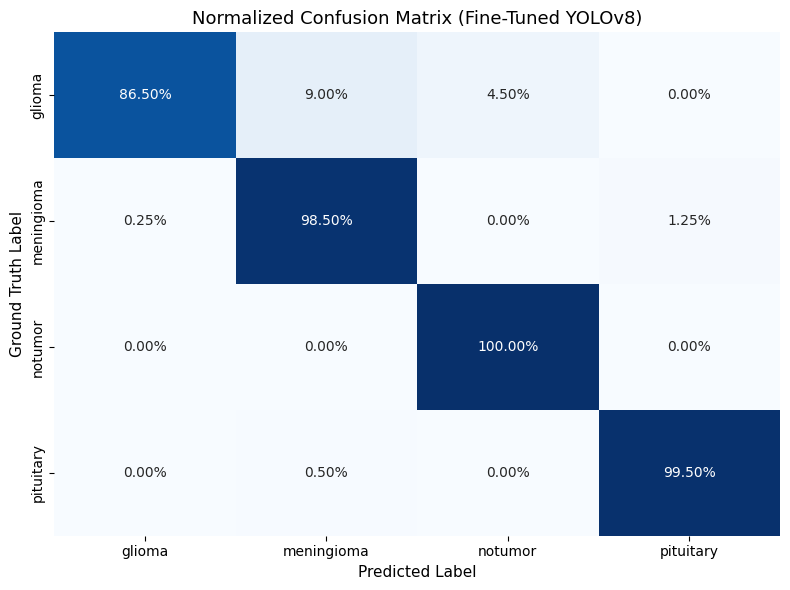

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

best_model = YOLO("brain_tumor_run/yolov8_mri/weights/best.pt")

y_true = []
y_pred = []

# Evaluate strictly on the untouched Testing directory
for cls_idx, cls_name in enumerate(classes):
    img_files = glob.glob(f"{test_path}/{cls_name}/*")
    
    # Run batch inference
    preds = best_model(img_files, verbose=False)
    
    for p in preds:
        pred_class_id = int(p.probs.top1)
        pred_class_name = p.names[pred_class_id]
        
        y_true.append(cls_name)
        y_pred.append(pred_class_name)

# Classification Report with Macro F1
report_str = classification_report(y_true, y_pred, target_names=classes, digits=4)
print("=" * 60)
print("             DETAILED CLASSIFICATION REPORT")
print("=" * 60)
print(report_str)

# Plot Normalized Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=classes)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", 
            xticklabels=classes, yticklabels=classes, cbar=False)
plt.title("Normalized Confusion Matrix (Fine-Tuned YOLOv8)", fontsize=13)
plt.xlabel("Predicted Label", fontsize=11)
plt.ylabel("Ground Truth Label", fontsize=11)
plt.tight_layout()
plt.show()

In [7]:
import shutil

# 1. Export the trained model directly to ONNX format
onnx_file = best_model.export(format="onnx", imgsz=224)

# 2. Copy the exported file to Kaggle's root working directory so it's easy to download
output_dest = "/kaggle/working/brain_tumor_yolo.onnx"
shutil.copyfile(onnx_file, output_dest)

print("=" * 60)
print(f"SUCCESS! ONNX model saved to: {output_dest}")
print(f"Model File Size: {os.path.getsize(output_dest) / (1024 * 1024):.2f} MB")
print("=" * 60)
print("You can now download 'brain_tumor_yolo.onnx' from the Output section on the right panel!")

Ultralytics 8.4.143 🚀 Python-3.12.13 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv8n-cls summary (fused): 30 layers, 1,440,004 parameters, 0 gradients, 0.4 GFLOPs

PyTorch: starting from 'brain_tumor_run/yolov8_mri/weights/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 4) (2.8 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 10 packages in 383ms
Prepared 1 package in 78ms
Installed 1 package in 14ms
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 1.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 1.9s, saved as 'brain_tumor_run/yolov8_mri/weights/best.onn